# Tutorial 7: Recovering a Wall Shape from Surface Pressure (2D Euler + JAX)

**Question.** A supersonic stream flows over a curved wall. We can *measure the pressure on the wall*, but we do not know the wall's shape. Can we recover the shape?

This is a **shape inverse problem**, and it is the first tutorial in this series where the forward model is a real flow solver and the gradient comes from **automatic differentiation** instead of a hand-derived adjoint (compare Tutorial 5).

**What you will learn**

1. How to write a small, differentiable 2D compressible Euler solver in JAX.
2. How to parameterise an unknown geometry with a few Fourier modes.
3. How to build a misfit + regularisation objective and get its exact gradient by differentiating *through* the time-marching loop.
4. How to hand that gradient to SciPy's L-BFGS-B, and watch the shape converge.
5. What this example does and does not prove (the "inverse crime" caveat at the end).

**Prerequisites.** Previous Tutorials (least squares with regularisation, adjoint thinking). Extra packages: `jax`, and `ffmpeg` only if you want to save the animation.

```bash
pip install jax scipy matplotlib
```

## 1. The setup in one picture

* Domain: the unit square $[0,1]\times[0,1]$, grid $80\times 40$.
* Free stream: Mach 2 flowing left to right, $\rho_\infty = p_\infty = 1$.
* Bottom boundary: a slip wall whose height is $y_w(x)$. Top: slip. Outlet: zero gradient.
* **Unknown:** $y_w(x)$. **Data:** the wall pressure (here expressed as $C_p$) and, for this tutorial, the pressure field.

The forward map is $\;p \;\longmapsto\; y_w \;\longmapsto\; \text{Euler flow} \;\longmapsto\; C_p(x)$.

The inverse problem asks us to invert it. As in Tutorials 1 to 4, the forward map is smooth and well behaved, so the real question is how stably we can go backwards.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
from jax import jit, value_and_grad
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import minimize
import functools

**Double precision.** `jax_enable_x64` is switched on at the top. Finite-difference gradients and L-BFGS line searches are much happier in float64; JAX defaults to float32.

## 2. Grid and flow constants

In [2]:
Nx = 80
Ny = 40

x = jnp.linspace(0,1,Nx)
y = jnp.linspace(0,1,Ny)

dx = x[1]-x[0]
dy = y[1]-y[0]

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [3]:
gamma = 1.4
Mach = 2.0

rho0 = 1.0
p0_fluid = 1.0

a0 = jnp.sqrt(gamma*p0_fluid/rho0)

u0 = Mach*a0
v0 = 0.0

q_inf = 0.5*rho0*u0**2

The speed of sound is $a_0=\sqrt{\gamma p_0/\rho_0}$, the inflow speed is $u_0 = M a_0$, and the dynamic pressure $q_\infty=\tfrac12\rho_0u_0^2$ is used to non-dimensionalise the pressure coefficient

$$C_p = \frac{p-p_0}{q_\infty}.$$

## 3. The unknown: a true shape and a Fourier parameterisation

We invent a "ground truth" wall, a gentle parabolic bump

$$y_{\text{true}}(x) = 0.12\,x(1-x),$$

and then pretend we do not know it. To recover it we describe candidate shapes with a short sine series

$$y(x;\mathbf p) = \sum_{k=1}^{5} p_k \sin(k\pi x), \qquad \mathbf p\in\mathbb R^5 .$$

Every term vanishes at $x=0$ and $x=1$, so the wall always meets the floor at both ends. The wall *slope* $y'(x)$ is what the flow actually sees, and it is available analytically.

> **Why only 5 modes?** This is regularisation by *parameterisation*: restricting the search space is a very strong prior and keeps the problem small. Section 8 shows why that also matters for honesty.

In [4]:
# TRUE Shape (Polynomial)


base_height = 0.0

def true_shape(x):
    return base_height + 0.12*x*(1-x)

def true_shape_dx(x):
    return 0.12*(1-2*x)

In [5]:
# Fourier Shape Parameterization


N_modes = 5

def shape(x,p):

    yvals = base_height*jnp.ones_like(x)

    for k in range(N_modes):
        yvals += p[k]*jnp.sin((k+1)*jnp.pi*x)

    return yvals

def dshape_dx(x,p):

    dy = jnp.zeros_like(x)

    for k in range(N_modes):
        dy += p[k]*(k+1)*jnp.pi*jnp.cos((k+1)*jnp.pi*x)

    return dy

## 4. The forward model: a 2D Euler solver

The compressible Euler equations in conservative form are

$$\partial_t \mathbf Q + \partial_x \mathbf F(\mathbf Q) + \partial_y \mathbf G(\mathbf Q) = 0,\qquad \mathbf Q=(\rho,\ \rho u,\ \rho v,\ E)^T,$$

with $p=(\gamma-1)\big(E-\tfrac12\rho(u^2+v^2)\big)$. `compute_states` converts $\mathbf Q$ to the fluxes, velocities and sound speed. Density and pressure are floored at $10^{-6}$ so a bad trial shape cannot produce a NaN during optimisation.

In [6]:
def compute_states(Q):

    rho = jnp.maximum(Q[0],1e-6)

    u = Q[1]/rho
    v = Q[2]/rho

    E = Q[3]

    p = (gamma-1)*(E-0.5*rho*(u**2+v**2))
    p = jnp.maximum(p,1e-6)

    a = jnp.sqrt(gamma*p/rho)

    Fx = jnp.array([
        rho*u,
        rho*u**2 + p,
        rho*u*v,
        (E+p)*u
    ])

    Fy = jnp.array([
        rho*v,
        rho*u*v,
        rho*v**2 + p,
        (E+p)*v
    ])

    return Fx,Fy,u,v,a

### The time-marching solver

Each step does the following.

1. **Time step** from the CFL condition, $\Delta t = 0.45\,\min(\Delta x/\lambda_x,\ \Delta y/\lambda_y)$ with $\lambda = |u|+a$.
2. **Interface fluxes** with a local Lax-Friedrichs (Rusanov) scheme: the central average minus a dissipation term $\tfrac12 S\,\Delta\mathbf Q$ with $S$ the larger of the two neighbouring wave speeds.
3. **Update** the interior cells.
4. **Boundary conditions:** fixed inlet, zero-gradient outlet, a mirrored top slip wall, and the *bottom wall condition*.

The bottom wall is where the unknown shape enters. Flow must be tangent to the wall, so the wall-normal velocity is $v_w = u\,y_w'(x)$. We impose this through a ghost row: $(\rho v)_0 = 2\rho_1 v_w - (\rho v)_1$. The solver therefore depends on the shape *only through its slope*.

The loop is a fixed 900 steps (`jax.lax.fori_loop`), a pseudo-time march towards the steady state. A fixed trip count is deliberate: it makes the whole solve a smooth, reverse-mode differentiable function of the parameters.

`true_wall=True` swaps in the exact polynomial slope; this is how the synthetic "measurements" are generated.

In [7]:
@functools.partial(jit, static_argnames=['true_wall'])
def solve_euler(p_params,true_wall=False):

    Q = jnp.zeros((4,Ny,Nx))

    Q = Q.at[0,:,:].set(rho0)
    Q = Q.at[1,:,:].set(rho0*u0)
    Q = Q.at[2,:,:].set(rho0*v0)
    Q = Q.at[3,:,:].set(p0_fluid/(gamma-1)+0.5*rho0*u0**2)

    if true_wall:
        slope = true_shape_dx(x)
    else:
        slope = dshape_dx(x,p_params)

    CFL = 0.45

    def step_fn(i,Qc):

        Fx,Fy,u,v,a = compute_states(Qc)

        maxx = jnp.max(jnp.abs(u)+a)
        maxy = jnp.max(jnp.abs(v)+a)

        dt = CFL*jnp.minimum(dx/maxx,dy/maxy)

        Fx_avg = 0.5*(Fx[:,:,:-1] + Fx[:,:,1:])
        Sx = jnp.maximum(jnp.abs(u[:,:-1])+a[:,:-1],jnp.abs(u[:,1:])+a[:,1:])
        Sx = Sx[jnp.newaxis,:,:]

        Fint = Fx_avg - 0.5*Sx*(Qc[:,:,1:] - Qc[:,:,:-1])

        Fy_avg = 0.5*(Fy[:,:-1,:] + Fy[:,1:,:])
        Sy = jnp.maximum(jnp.abs(v[:-1,:])+a[:-1,:],jnp.abs(v[1:,:])+a[1:,:])
        Sy = Sy[jnp.newaxis,:,:]

        Gint = Fy_avg - 0.5*Sy*(Qc[:,1:,:] - Qc[:,:-1,:])

        dQdx = (Fint[:,1:-1,1:] - Fint[:,1:-1,:-1])/dx
        dQdy = (Gint[:,1:,1:-1] - Gint[:,:-1,1:-1])/dy

        Qn = Qc.at[:,1:-1,1:-1].add(-dt*(dQdx+dQdy))

        # inlet
        Qn = Qn.at[0,:,0].set(rho0)
        Qn = Qn.at[1,:,0].set(rho0*u0)
        Qn = Qn.at[2,:,0].set(rho0*v0)
        Qn = Qn.at[3,:,0].set(p0_fluid/(gamma-1)+0.5*rho0*u0**2)

        # outlet
        Qn = Qn.at[:,:,-1].set(Qn[:,:,-2])

        # top slip
        Qn = Qn.at[:,-1,:].set(Qn[:,-2,:])
        Qn = Qn.at[2,-1,:].set(-Qn[2,-2,:])

        # bottom wall
        Qn = Qn.at[:,0,:].set(Qn[:,1,:])

        u_int = Qn[1,1,:]/Qn[0,1,:]

        v_wall = u_int*slope

        Qn = Qn.at[2,0,:].set(2*Qn[0,1,:]*v_wall - Qn[2,1,:])

        return Qn

    Qf = jax.lax.fori_loop(0,900,step_fn,Q)

    return Qf

## 5. Pressure, pressure coefficient 

In [8]:
# Pressure


@jit
def get_pressure(Q):

    rho = jnp.maximum(Q[0],1e-6)

    u = Q[1]/rho
    v = Q[2]/rho

    E = Q[3]

    p = (gamma-1)*(E-0.5*rho*(u**2+v**2))

    return jnp.maximum(p,1e-6)

In [9]:
# Pressure Coefficient


def Cp(p):
    return (p-p0_fluid)/q_inf

We now run the solver once with the *true* wall to create the target data $P_\text{target}$. In a real experiment this would be a pressure-tap or PSP measurement; here it is a simulation, so there is no noise.

In [10]:
# Target Flow


print("Computing target flow")

def solve_true():

    Q = solve_euler(jnp.zeros(N_modes),true_wall=True)

    return Q

Q_target = solve_true()

P_target = get_pressure(Q_target)

Computing target flow


## 6. The objective function

$$J(\mathbf p) \;=\; \underbrace{\overline{\big(C_p^{\text{wall}}(\mathbf p)-C_p^{\text{target}}\big)^2}}_{\text{wall-pressure misfit}} \;+\; 0.2\,\underbrace{\overline{\big(P(\mathbf p)-P_\text{target}\big)^2}}_{\text{field misfit}} \;+\; \underbrace{10^{-4}\,\lVert\mathbf p\rVert^2}_{\text{Tikhonov}} .$$

* The wall $C_p$ is taken as the average of the first two grid rows, because the wall sits between the ghost row and the first interior row.
* The Tikhonov term is exactly the penalty from Tutorial 4. It discourages large coefficients, which here would mean needlessly wiggly walls.
* The field term gives the optimiser extra information. Be aware it assumes you have the full pressure field, which is unrealistic in practice; try dropping it in Exercise 2.

In [11]:
# Objective Function


def objective(p):

    Q = solve_euler(p,true_wall=False)

    P = get_pressure(Q)

    cp_wall = Cp(0.5*(P[0,:]+P[1,:]))
    cp_target = Cp(0.5*(P_target[0,:]+P_target[1,:]))

    pressure_loss = jnp.mean((cp_wall-cp_target)**2)

    field_loss = jnp.mean((P-P_target)**2)

    reg = 1e-4*jnp.sum(p**2)

    return pressure_loss + 0.2*field_loss + reg

### Gradients for free

`value_and_grad` differentiates the whole pipeline, from the five Fourier coefficients through 900 solver steps to the scalar $J$. This is **reverse-mode automatic differentiation**, which is the discrete adjoint method of Tutorial 5 generated by the compiler instead of by hand. The cost of one gradient is a small multiple of one forward solve, independent of the number of parameters.

SciPy expects NumPy arrays, so `scipy_wrap` converts in and out.

In [12]:
@jit
def obj_grad(p):
    return value_and_grad(objective)(p)

def scipy_wrap(p):

    val,grad = obj_grad(jnp.array(p))

    return np.array(val),np.array(grad)

## 7. Optimisation

We start from a flat wall, $\mathbf p=\mathbf 0$, and run L-BFGS-B with box bounds $|p_k|\le 0.2$ and at most 40 iterations. The `callback` stores every iterate so we can animate the convergence afterwards.

In [13]:
# Optimization


p0 = np.zeros(N_modes)

history=[p0.copy()]

def callback(xk):

    history.append(xk.copy())

    print("iter",len(history))

print("Starting Optimization")

res = minimize(
    scipy_wrap,
    p0,
    method="L-BFGS-B",
    jac=True,
    callback=callback,
    bounds=[(-0.2,0.2)]*N_modes,
    options={"maxiter":40}
)

p_opt = res.x

print("Recovered parameters:",p_opt)

Starting Optimization
iter 2
iter 3
iter 4
iter 5
iter 6
iter 7
iter 8
iter 9
iter 10
iter 11
Recovered parameters: [ 3.07700129e-02 -1.96229089e-05  1.08689869e-03 -9.97582686e-06
  2.08930179e-04]


The optimiser stopped after about ten iterations. Look at the recovered coefficients:

* $p_1\approx 0.0308$ dominates; all higher modes are about $10^{-3}$ or smaller.
* That is what we expect. Projecting the parabola $0.12\,x(1-x)$ onto $\sin(\pi x)$ gives $0.12\cdot 8/\pi^3\approx 0.0310$, and the parabola has almost no energy in the higher sine modes.

Shape RMS error: 0.0001618990660953578


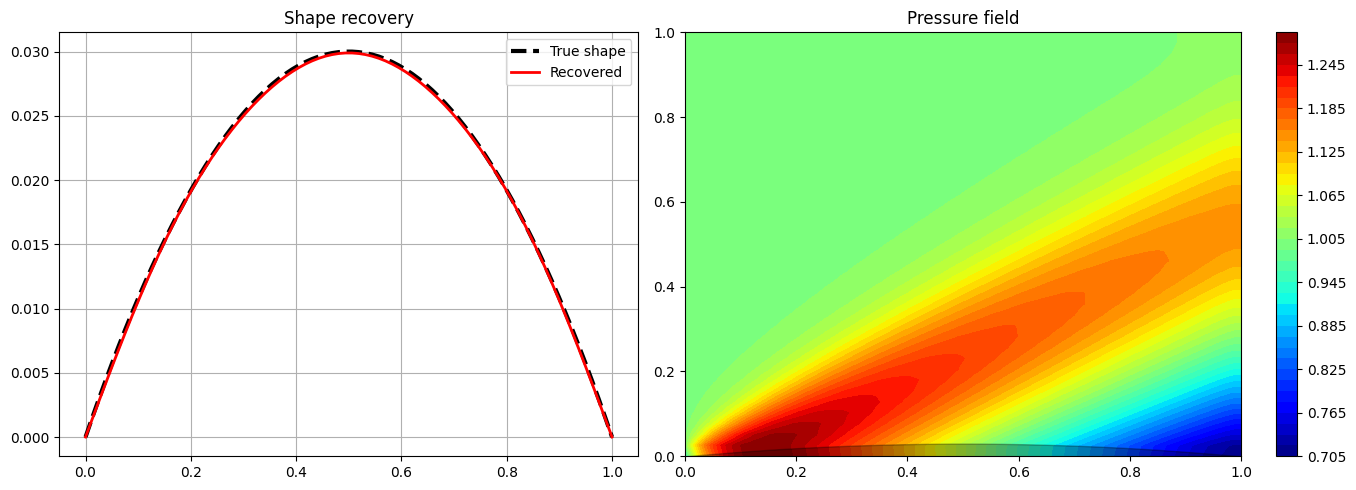

In [14]:
# Final Plot


x_np = np.array(x)

y_true = true_shape(x_np)
y_rec = shape(x_np,p_opt)

shape_error = np.sqrt(np.mean((y_true-y_rec)**2))
print("Shape RMS error:",shape_error)

Q_final = solve_euler(jnp.array(p_opt),true_wall=False)

P_final = np.array(get_pressure(Q_final))

fig = plt.figure(figsize=(14,5))

gs = gridspec.GridSpec(1,2,width_ratios=[1,1.2])

ax1 = plt.subplot(gs[0])

ax1.plot(x_np,y_true,'k--',lw=3,label="True shape")
ax1.plot(x_np,y_rec,'r',lw=2,label="Recovered")

ax1.set_title("Shape recovery")
ax1.legend()
ax1.grid()

ax2 = plt.subplot(gs[1])

X,Y = np.meshgrid(x_np,np.array(y))

cont = ax2.contourf(X,Y,P_final,50,cmap='jet')

fig.colorbar(cont,ax=ax2)

ax2.fill_between(x_np,0,y_rec,color='black',alpha=0.3)

ax2.set_title("Pressure field")

plt.tight_layout()

plt.show()

**Result.** The recovered wall lies on top of the true one, with an RMS error of about $1.6\times10^{-4}$, i.e. roughly 0.1% of the shape's maximum height of 0.03. The right panel shows the pressure field of the recovered flow, with the recovered body in grey.

### Watching it converge

The next cell replays the stored optimiser history as an animation. It linearly interpolates between iterates, re-runs the flow solver at each frame, and writes `shape_optimization.mp4`. It needs `ffmpeg` and takes a while, because it performs 100 forward solves. Skip it if you only want the numbers.

In [15]:
import matplotlib.animation as animation

print("Generating animation...")

fps = 10
duration = 10
frames = fps * duration   # 100 frames

# interpolate optimization history
indices = np.linspace(0, len(history)-1, frames)

fig = plt.figure(figsize=(10,4))

ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

X, Y = np.meshgrid(np.array(x), np.array(y))
x_np = np.array(x)

def update(frame):

    ax1.clear()
    ax2.clear()

    # interpolate parameter vector
    i = indices[frame]

    i0 = int(np.floor(i))
    i1 = min(i0+1, len(history)-1)

    w = i - i0

    p = (1-w)*history[i0] + w*history[i1]

    # geometry
    y_rec = np.array(shape(x, jnp.array(p)))
    y_true = true_shape(x_np)

    # flow
    Q = solve_euler(jnp.array(p), true_wall=False)
    P = np.array(get_pressure(Q))

    # plot geometry
    ax1.plot(x_np, y_true, 'k--', lw=3, label="True")
    ax1.plot(x_np, y_rec, 'r', lw=2, label="Recovered")

    ax1.set_ylim(-0.02,0.15)
    ax1.set_title(f"Optimization progress")
    ax1.legend()
    ax1.grid()

    # pressure field
    cont = ax2.contourf(X, Y, P, 50, cmap='jet')
    ax2.fill_between(x_np,0,y_rec,color='black',alpha=0.4)

    ax2.set_title("Pressure field")

    return cont

anim = animation.FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100
)

writer = animation.FFMpegWriter(fps=fps)

anim.save("shape_optimization.mp4", writer=writer)

plt.close()

print("Animation saved as shape_optimization.mp4")

Generating animation...
Animation saved as shape_optimization.mp4


## 8. What we learned, and the caveats

**What worked**

* Exact gradients by automatic differentiation made a 5-parameter shape inversion converge in about ten L-BFGS iterations. No finite-difference gradient was needed.
* A low-dimensional Fourier basis plus a small Tikhonov term kept the problem well-posed.

**Caveats you should not skip**

1. **Inverse crime.** The data were generated by the same solver, on the same grid, with no noise. Any numerical error in the scheme cancels exactly. Real data would break this.
2. **Noise.** Tutorials 2 and 3 showed how noise destroys naive inverses. Here the parameterisation protects us, but with 20 or 50 modes you would see the same noise amplification return.
3. **Full-field data.** The field misfit term uses pressure everywhere. Real experiments often provide only wall pressure.
4. **Truncation.** A parabola is not exactly in the span of five sine modes, so a small bias remains even with perfect data.
5. **Non-uniqueness.** Only the wall slope enters the flow, so the shape is determined up to what the boundary conditions fix (here, zero height at both ends).

## Exercises

1. **Noise.** Add Gaussian noise (1% of the dynamic pressure) to `P_target` and re-run. How does the shape error change? Then increase `N_modes` to 15 and compare.
2. **Wall data only.** Set the field-misfit weight from `0.2` to `0` so only wall $C_p$ is used. Does the recovery degrade? Why?
3. **Regularisation sweep.** Vary the Tikhonov weight over $10^{-8},\dots,10^{-2}$ and plot shape error against weight. Is there an L-curve as in Tutorial 4?
4. **Different truth.** Replace `true_shape` with a shape that is *not* smooth, such as a ramp or a tent. What does the 5-mode basis do to it?
5. **Gradient check.** Compare `jax.grad(objective)` with a central finite difference at a random `p`. Which step size gives the best agreement, and why?
6. **Inverse crime.** Generate the target on a finer grid (say $160\times80$) and interpolate it onto the inversion grid. How much of the error is now due to the discretisation?